# Which cells couple low oxygen to FLT1? + two-cohort meta-analysis (Addendum D)

Addendum D was committed before this notebook was run. **All analyses here are post hoc and exploratory.**
Run notebooks 01–05 first.

- **D1** For each of 14 placental cell classes (independent single-cell data): within preeclampsia donors,
  does the hypoxia score track FLT1, and is FLT1 unusually strongly coupled compared with all other genes?
- **D1b** Is the hypoxia score higher in PE in each cell class?
- **D2** Fixed- and random-effects pooling of the two bulk cohorts.

In [1]:
import os, sys, warnings
from pathlib import Path
if "google.colab" in sys.modules:
    os.chdir("/content/team/notebooks")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ROOT = Path(".."); DATA_DIR = ROOT / "openbio-datathon-2026" / "track-01" / "data"
FIG_DIR = ROOT / "figures"; RES_DIR = Path("results")
gmt = {l.split("\t")[0]: l.rstrip("\n").split("\t")[2:] for l in open(ROOT / "data_external" / "h.all.v2024.1.Hs.symbols.gmt")}
HYP = sorted(set(gmt["HALLMARK_HYPOXIA"]))

pb = pd.read_csv(DATA_DIR / "extension" / "pseudobulk" / "track01_pseudobulk_counts.csv", index_col=0)
pbm = pd.read_csv(DATA_DIR / "extension" / "pseudobulk" / "track01_pseudobulk_metadata.csv", index_col=0)
MIN_CELLS, MIN_DONORS = 20, 6

def class_matrix(cls, donor_mask):
    md = pbm[(pbm.cell_class == cls) & donor_mask & (pbm.n_cells >= MIN_CELLS)]
    c = pb[md.index]
    c = c.loc[(c >= 10).sum(axis=1) >= 3]
    lc = np.log2(c / c.sum() * 1e6 + 1)
    return md, lc

def hyp_score(lc):
    z = lc.sub(lc.mean(1), axis=0).div(lc.std(1).replace(0, np.nan), axis=0)
    return z.loc[z.index.intersection(HYP)].mean()

## D1. Hypoxia–FLT1 coupling within PE donors, per cell class
Specificity control: correlate the hypoxia score with **every** other expressed gene (not in the hypoxia set)
and ask where FLT1 ranks. A high rank means the coupling is not just "everything goes up together".

In [2]:
rows = []
for donor_set, mask in [("early PE", pbm.clinical_group == "PE_early"), ("all PE", pbm.pe_status == "PE")]:
    for cls in sorted(pbm.cell_class.unique()):
        md, lc = class_matrix(cls, mask)
        row = {"donor_set": donor_set, "cell_class": cls, "n_donors": len(md),
               "median_cells": md.n_cells.median() if len(md) else np.nan}
        if len(md) < MIN_DONORS or "FLT1" not in lc.index:
            row["status"] = "skipped (too few donors or FLT1 not expressed)"
            rows.append(row); continue
        h = hyp_score(lc)
        others = lc.drop(index=[g for g in lc.index if g in set(HYP)])
        # rank-based correlation of every other gene with the score
        rh = stats.rankdata(h); ro = others.rank(axis=1).values
        rh_c = (rh - rh.mean()) / np.sqrt(((rh - rh.mean()) ** 2).sum())
        ro_c = ro - ro.mean(axis=1, keepdims=True)
        denom = np.sqrt((ro_c ** 2).sum(axis=1)); denom[denom == 0] = np.nan
        all_rho = pd.Series((ro_c @ rh_c) / denom, index=others.index).dropna()
        r, p = stats.spearmanr(h, lc.loc["FLT1"])
        row.update({"status": "ok", "FLT1_cpm_median": float((2 ** lc.loc["FLT1"] - 1).median()),
                    "rho_FLT1": r, "p_FLT1": p, "FLT1_percentile": float((all_rho < all_rho["FLT1"]).mean() * 100),
                    "median_rho_all_genes": float(all_rho.median()), "n_genes_compared": len(all_rho)})
        row["FLT1_specific"] = bool(r > 0 and p < 0.05 and row["FLT1_percentile"] >= 95)
        rows.append(row)
d1 = pd.DataFrame(rows); d1.to_csv(RES_DIR / "D1_flt1_coupling_by_cell_class.csv", index=False)
pd.set_option("display.width", 220)
print(d1[d1.donor_set == "early PE"].drop(columns="donor_set").round(3).to_string(index=False))
print()
print(d1[d1.donor_set == "all PE"].drop(columns="donor_set").round(3).to_string(index=False))

              cell_class  n_donors  median_cells                                         status  FLT1_cpm_median  rho_FLT1  p_FLT1  FLT1_percentile  median_rho_all_genes  n_genes_compared FLT1_specific
                  b_cell         2          35.0 skipped (too few donors or FLT1 not expressed)              NaN       NaN     NaN              NaN                   NaN               NaN           NaN
        endothelial_cell        10         409.0                                             ok          273.440     0.770   0.009           99.003                -0.067           13035.0          True
extravillous_trophoblast         7         100.0                                             ok         4154.489     0.929   0.003           98.854                 0.071           10123.0          True
           hofbauer_cell        10         202.5                                             ok           47.241     0.636   0.048           96.174                -0.067           11397.0     

## D1b. Is the hypoxia score higher in PE within each cell class? (all donors, adjusted for gestational age)

In [3]:
rows = []
for cls in sorted(pbm.cell_class.unique()):
    md, lc = class_matrix(cls, pbm.pe_status.notna())
    if len(md) < 10:
        continue
    d = md[["pe_status", "ga_delivery_weeks"]].copy(); d["PE"] = (d.pe_status == "PE").astype(int)
    d["hyp"] = hyp_score(lc).values
    if d.PE.nunique() < 2:
        continue
    f = smf.ols("hyp ~ PE + ga_delivery_weeks", data=d).fit()
    rows.append({"cell_class": cls, "n": len(d), "n_PE": int(d.PE.sum()), "PE_coef": f.params["PE"],
                 "CI_low": f.conf_int().loc["PE", 0], "CI_high": f.conf_int().loc["PE", 1], "p": f.pvalues["PE"]})
d1b = pd.DataFrame(rows); d1b["q_BH"] = multipletests(d1b.p, method="fdr_bh")[1]
d1b = d1b.sort_values("PE_coef", ascending=False); d1b.to_csv(RES_DIR / "D1b_hypoxia_PE_by_cell_class.csv", index=False)
print(d1b.round(3).to_string(index=False))

              cell_class  n  n_PE  PE_coef  CI_low  CI_high     p  q_BH
extravillous_trophoblast 15    12    0.306   0.074    0.538 0.014 0.069
     syncytiotrophoblast 26    17    0.296   0.070    0.523 0.013 0.069
 villous_cytotrophoblast 26    17    0.244   0.042    0.445 0.020 0.069
              macrophage 25    16    0.237   0.029    0.444 0.027 0.077
                  t_cell 23    14    0.219  -0.090    0.527 0.155 0.197
            stromal_cell 26    17    0.210  -0.010    0.429 0.060 0.121
      smooth_muscle_cell 25    16    0.206   0.041    0.371 0.017 0.069
        endothelial_cell 26    17    0.180   0.009    0.351 0.040 0.093
                monocyte 26    17    0.166  -0.020    0.353 0.078 0.137
                pericyte 26    17    0.143  -0.058    0.345 0.154 0.197
           hofbauer_cell 26    17    0.142  -0.023    0.307 0.089 0.138
                 nk_cell 26    17    0.094  -0.070    0.258 0.249 0.290
                  b_cell 13     8    0.081  -0.132    0.294 0.41

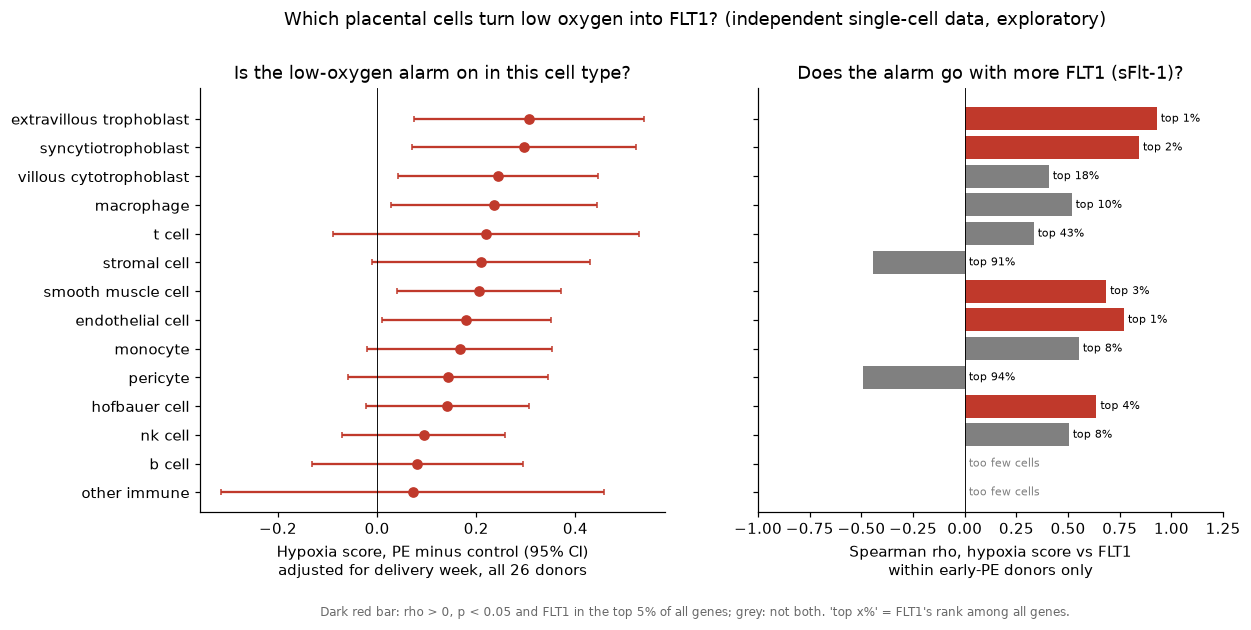

In [4]:
ok = d1[(d1.donor_set == "early PE") & (d1.status == "ok")].set_index("cell_class")
order = d1b.cell_class.tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
y = np.arange(len(order))
sub = d1b.set_index("cell_class").loc[order]
axes[0].errorbar(sub.PE_coef, y, xerr=[sub.PE_coef - sub.CI_low, sub.CI_high - sub.PE_coef], fmt="o",
                 c="#c0392b", capsize=2)
axes[0].axvline(0, c="k", lw=0.6)
axes[0].set_xlabel("Hypoxia score, PE minus control (95% CI)\nadjusted for delivery week, all 26 donors")
axes[0].set_title("Is the low-oxygen alarm on in this cell type?")
for i, cls in enumerate(order):
    if cls in ok.index:
        r = ok.loc[cls]
        col = "#c0392b" if r.FLT1_specific else ("#e6a09a" if (r.rho_FLT1 > 0 and r.p_FLT1 < 0.05) else "grey")
        axes[1].barh(i, r.rho_FLT1, color=col)
        axes[1].text(max(r.rho_FLT1, 0) + 0.02, i, f"top {100 - r.FLT1_percentile:.0f}%", va="center", fontsize=7.5)
    else:
        axes[1].text(0.02, i, "too few cells", va="center", fontsize=7.5, color="grey")
axes[1].axvline(0, c="k", lw=0.6); axes[1].set_xlim(-1, 1.25)
axes[1].set_xlabel("Spearman rho, hypoxia score vs FLT1\nwithin early-PE donors only")
axes[1].set_title("Does the alarm go with more FLT1 (sFlt-1)?")
axes[0].set_yticks(y); axes[0].set_yticklabels([c.replace("_", " ") for c in order]); axes[0].invert_yaxis()
fig.suptitle("Which placental cells turn low oxygen into FLT1? (independent single-cell data, exploratory)", y=1.02)
fig.text(0.5, -0.08, "Dark red bar: rho > 0, p < 0.05 and FLT1 in the top 5% of all genes; grey: not both. "
         "'top x%' = FLT1's rank among all genes.", ha="center", fontsize=8, color="dimgrey")
plt.savefig(FIG_DIR / "fig10_celltype_flt1_coupling.png", dpi=300, bbox_inches="tight"); plt.show()

## D2. Two-cohort meta-analysis of the hypoxia-only contrasts

In [5]:
a2 = pd.read_csv(RES_DIR / "A2_A3_group_contrasts.csv"); a2 = a2[(a2.se == "nonrobust") & (a2.score == "hypoxia-only genes")].set_index("contrast")
c1 = pd.read_csv(RES_DIR / "C1_GSE114691_contrasts.csv"); c1 = c1[c1.score == "hypoxia-only genes"].set_index("contrast")
pairs = {"EOPE vs preterm control": ("EOPE vs iPTB", "EOPE vs control"),
         "PE (both) vs growth-restriction-only": ("PE (both) vs FGR-only", "PE (both) vs IUGR-only"),
         "Growth-restriction-only vs preterm control": ("FGR-only vs iPTB", "IUGR-only vs control")}
rows = []
for name, (k1, k2) in pairs.items():
    est = np.array([a2.loc[k1, "estimate"], c1.loc[k2, "estimate"]])
    se = np.array([a2.loc[k1, "std_err"], c1.loc[k2, "std_err"]])  # Addendum E0: model SEs, not CI/(2*1.96)
    w = 1 / se ** 2; fe = (w * est).sum() / w.sum(); fe_se = np.sqrt(1 / w.sum())
    Q = (w * (est - fe) ** 2).sum(); I2 = max(0.0, (Q - 1) / Q) * 100 if Q > 0 else 0.0
    tau2 = max(0.0, (Q - 1) / (w.sum() - (w ** 2).sum() / w.sum()))
    wr = 1 / (se ** 2 + tau2); re = (wr * est).sum() / wr.sum(); re_se = np.sqrt(1 / wr.sum())
    rows.append({"contrast": name, "est_GSE203507": est[0], "est_GSE114691": est[1],
                 "fixed": fe, "fixed_CI_low": fe - 1.96 * fe_se, "fixed_CI_high": fe + 1.96 * fe_se,
                 "fixed_p": 2 * stats.norm.sf(abs(fe / fe_se)),
                 "random": re, "random_CI_low": re - 1.96 * re_se, "random_CI_high": re + 1.96 * re_se,
                 "random_p": 2 * stats.norm.sf(abs(re / re_se)), "Q": Q, "Q_p": stats.chi2.sf(Q, 1), "I2_pct": I2})
d2 = pd.DataFrame(rows); d2.to_csv(RES_DIR / "D2_meta_analysis.csv", index=False)
print(d2.round(3).T.to_string())

                                      0                                     1                                           2
contrast        EOPE vs preterm control  PE (both) vs growth-restriction-only  Growth-restriction-only vs preterm control
est_GSE203507                     0.424                                 0.297                                       0.043
est_GSE114691                     0.213                                 0.111                                       0.116
fixed                             0.269                                  0.16                                       0.099
fixed_CI_low                       0.14                                 0.042                                      -0.037
fixed_CI_high                     0.399                                 0.278                                       0.234
fixed_p                             0.0                                 0.008                                       0.153
random                  

### D1c (post hoc, added after seeing D1): is the STB/EVT coupling really stronger than in cytotrophoblast?
Paired bootstrap over early-PE donors present in both classes (2,000 resamples, seed 42).

In [6]:
rng = np.random.default_rng(42)
def coupling(cls, donors):
    md, lc = class_matrix(cls, pbm.donor_id.isin(donors))
    h = hyp_score(lc); f = lc.loc["FLT1"]
    return pd.DataFrame({"h": h.values, "f": f.values}, index=md.donor_id.values)
early = pbm.loc[pbm.clinical_group == "PE_early", "donor_id"].unique()
rows = []
for a, b in [("syncytiotrophoblast", "villous_cytotrophoblast"), ("extravillous_trophoblast", "villous_cytotrophoblast"),
             ("endothelial_cell", "villous_cytotrophoblast")]:
    A, Bc = coupling(a, early), coupling(b, early)
    shared = sorted(set(A.index) & set(Bc.index))
    A, Bc = A.loc[shared], Bc.loc[shared]
    obs = stats.spearmanr(A.h, A.f)[0] - stats.spearmanr(Bc.h, Bc.f)[0]
    boots = []
    for _ in range(2000):
        s = rng.choice(len(shared), len(shared), replace=True)
        if len(set(s)) < 4: continue
        ra = stats.spearmanr(A.h.values[s], A.f.values[s])[0]; rb = stats.spearmanr(Bc.h.values[s], Bc.f.values[s])[0]
        if np.isfinite(ra) and np.isfinite(rb): boots.append(ra - rb)
    boots = np.array(boots)
    rows.append({"comparison": f"{a} minus {b}", "n_shared_donors": len(shared), "rho_difference": obs,
                 "boot_CI_low": np.quantile(boots, 0.025), "boot_CI_high": np.quantile(boots, 0.975),
                 "boot_frac_le_0": float((boots <= 0).mean())})
d1c = pd.DataFrame(rows); d1c.to_csv(RES_DIR / "D1c_coupling_difference.csv", index=False); print(d1c.round(3).to_string(index=False))

                                            comparison  n_shared_donors  rho_difference  boot_CI_low  boot_CI_high  boot_frac_le_0
     syncytiotrophoblast minus villous_cytotrophoblast               10           0.436       -0.131         1.235           0.095
extravillous_trophoblast minus villous_cytotrophoblast                7           0.357       -0.302         1.407           0.213
        endothelial_cell minus villous_cytotrophoblast               10           0.364       -0.385         1.116           0.185
